# Our method: better FTD detection
The baselines (notebook 02) call most FTD subjects AD. Our method changes three things:

1. **One row per person** (median of each feature over their epochs) instead of thousands of epochs, so the model learns disease patterns rather than recognising individuals.
2. **Regional features** (5 brain regions instead of 19 channels), so there are fewer features for 88 people.
3. **FTD-targeted features**: peak alpha frequency, spectral entropy, front-vs-back power ratios (FTD affects the front of the brain, AD the back) and coherence between regions.

The classifier is the same random forest as the baseline, so the gain comes from the changes above. Same subject-level 5-fold CV, 10 shuffles.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from src.features import (load_spectra, load_coherence, feature_table, regional_table,
                          extra_spectral_features, per_subject, method_table)
from src.models import make_rf, TwoStep
from src.evaluate import subject_cv, repeat_cv
from src.config import RESULTS

spec = load_spectra()
coh = load_coherence()                                   # connectivity, cached after the first run
bands = feature_table(spec)                              # baseline features, one row per epoch
extra = extra_spectral_features(spec["freqs"], spec["power"], spec["ch_names"])
ours = method_table(spec, coh)                           # our features, one row per person
print(bands.shape, ours.shape)

(17419, 116) (88, 77)


## Step by step (AD vs FTD vs CN)
Each row adds one change, so we can see what helps.

In [2]:
classes = ["AD", "FTD", "CN"]
steps = {
    "Baseline: RF, epochs, channel band power": (bands, make_rf),
    "+ one row per person":                      (per_subject(bands), make_rf),
    "+ regional features":                       (per_subject(regional_table(bands)), make_rf),
    "+ peak alpha, entropy, front/back":         (per_subject(pd.concat([regional_table(bands), extra], axis=1)), make_rf),
    "+ coherence (our method)":                  (ours, make_rf),
    "Our method, two-step classifier":           (ours, lambda: TwoStep(make_rf, healthy=2)),
}

rows = []
for name, (table, make_model) in steps.items():
    row = repeat_cv(table, make_model, classes)
    row["method"] = name
    rows.append(row)

ablation = pd.DataFrame(rows).set_index("method").round(3)
print(ablation.to_string())
ablation.to_csv(RESULTS / "our_method_ablation.csv")

                                          accuracy  macro_f1  recall_AD  recall_FTD  recall_CN
method                                                                                        
Baseline: RF, epochs, channel band power     0.644     0.588      0.775       0.217      0.821
+ one row per person                         0.551     0.530      0.589       0.335      0.676
+ regional features                          0.550     0.535      0.569       0.378      0.662
+ peak alpha, entropy, front/back            0.597     0.581      0.594       0.422      0.738
+ coherence (our method)                     0.624     0.604      0.619       0.409      0.800
Our method, two-step classifier              0.599     0.566      0.589       0.322      0.831


## Baseline vs our method on every task

In [3]:
tasks = [["AD", "FTD", "CN"], ["AD", "FTD"], ["FTD", "CN"], ["AD", "CN"]]
rows = []
for classes in tasks:
    for name, table in [("Baseline RF", bands), ("Our method", ours)]:
        row = repeat_cv(table, make_rf, classes)
        row.update({"task": "-".join(classes), "method": name})
        rows.append(row)

versus = pd.DataFrame(rows).round(3)
versus = versus[["task", "method", "accuracy", "macro_f1", "recall_AD", "recall_FTD", "recall_CN"]]
print(versus.to_string(index=False))
versus.to_csv(RESULTS / "our_method_vs_baseline.csv", index=False)

     task      method  accuracy  macro_f1  recall_AD  recall_FTD  recall_CN
AD-FTD-CN Baseline RF     0.644     0.588      0.775       0.217      0.821
AD-FTD-CN  Our method     0.624     0.604      0.619       0.409      0.800
   AD-FTD Baseline RF     0.634     0.519      0.919       0.187        NaN
   AD-FTD  Our method     0.585     0.566      0.647       0.487        NaN
   FTD-CN Baseline RF     0.773     0.764        NaN       0.652      0.869
   FTD-CN  Our method     0.790     0.785        NaN       0.726      0.841
    AD-CN Baseline RF     0.822     0.820      0.808         NaN      0.838
    AD-CN  Our method     0.785     0.783      0.772         NaN      0.800


## Where the mistakes go
Confusion matrices pooled over 10 shuffles, as a fraction of each true class.

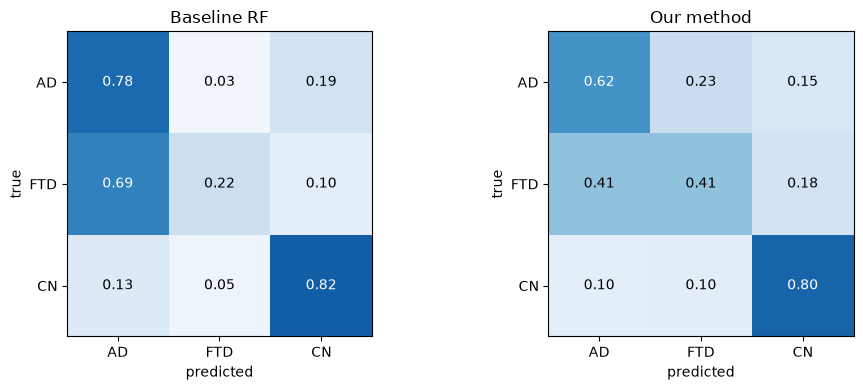

In [4]:
classes = ["AD", "FTD", "CN"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, table) in zip(axes, [("Baseline RF", bands), ("Our method", ours)]):
    res = pd.concat([subject_cv(table, make_rf, classes, seed) for seed in range(10)])
    cm = confusion_matrix(res.true, res.guess, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3), classes)
    ax.set_yticks(range(3), classes)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(name)
plt.tight_layout()
plt.savefig(RESULTS / "confusion_baseline_vs_ours.png", dpi=120)
plt.show()

## Which features does our method use most?

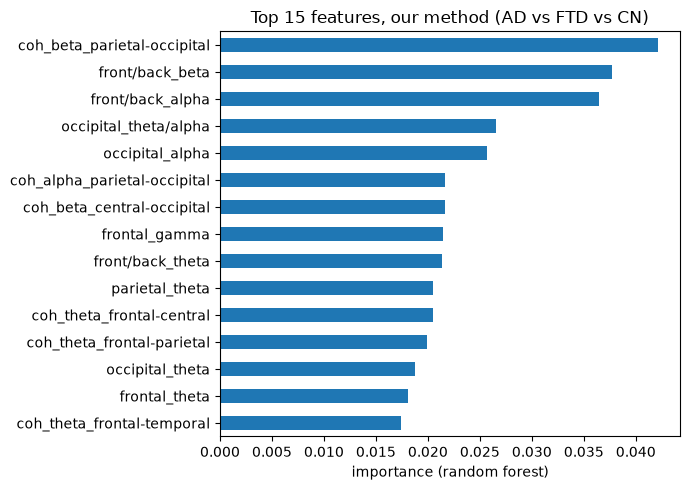

In [5]:
X = ours.drop(columns=["subject", "label"])
rf = make_rf().fit(X.values, ours.label.values)
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

ax = importance.tail(15).plot.barh(figsize=(7, 5))
ax.set_xlabel("importance (random forest)")
ax.set_title("Top 15 features, our method (AD vs FTD vs CN)")
plt.tight_layout()
plt.savefig(RESULTS / "our_method_features.png", dpi=120)
plt.show()